# Data Exploration

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

### 


In [6]:
# Reading the data 
df = pd.read_csv("Data/price_data.csv", header = 3)
df["Date"] = pd.to_datetime(df['Date'])
df.set_index("Date", inplace=True)
df.head()

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_12154/3791631968.py:2: DtypeWarning: Columns (5,64,138,248,268,280,322,355,367,396,447,450,472,509) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Data/price_data.csv", header = 3)


,Line#,LYB UN,AXP UN,VZ UN,TPL UN,AVGO UW,BA UN,SOLV UN,CAT UN,JPM UN,...,ZTS UN,ARES UN,COIN UW,EQIX UW,DLR UN,MOH UN,LVS UN,Unnamed: 546,Unnamed: 547,Unnamed: 548
Date,,,,,,,,,,,,,,,,,,,,,
2010-07-30,6,NaN,36.08,13.66,7.62,1.56,53.77,NaN,47.87,27.04,...,NaN,NaN,NaN,70.34,34.63,19.87,17.26,NaN,NaN,NaN
2010-08-02,9,NaN,36.36,13.90,7.91,1.57,54.99,NaN,48.76,27.95,...,NaN,NaN,NaN,70.71,35.02,20.33,17.96,NaN,NaN,NaN
2010-08-03,10,NaN,36.05,13.89,7.93,1.55,54.87,NaN,48.30,27.57,...,NaN,NaN,NaN,70.74,34.43,20.69,18.07,NaN,NaN,NaN
2010-08-04,11,NaN,35.65,13.82,8.06,1.60,54.98,NaN,48.81,27.72,...,NaN,NaN,NaN,70.88,34.06,21.14,18.56,NaN,NaN,NaN
2010-08-05,12,NaN,34.93,13.89,8.06,1.63,54.55,NaN,49.39,27.70,...,NaN,NaN,NaN,70.71,33.23,18.87,18.35,NaN,NaN,NaN


In [10]:
df["BA UN"]


Date
2010-07-30     53.77
2010-08-02     54.99
2010-08-03     54.87
2010-08-04     54.98
2010-08-05     54.55
               ...  
2025-07-23    233.88
2025-07-24    231.27
2025-07-25    233.06
2025-07-28    236.41
2025-07-29    226.08
Name: BA UN, Length: 3773, dtype: float64

<Axes: xlabel='Date'>

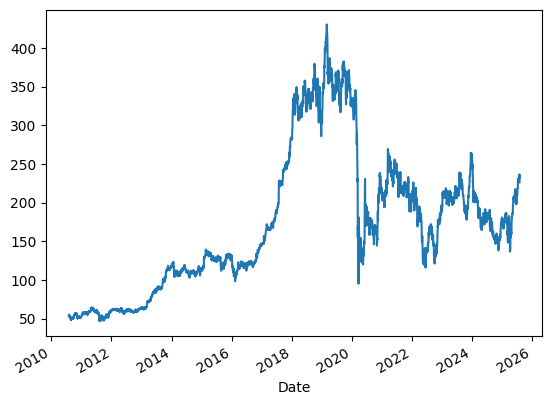

In [8]:
test_stock = df["BA UN"]
test_stock.plot()

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_12154/428286594.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  test_stock.pct_change().dropna().plot()


<Axes: xlabel='Date'>

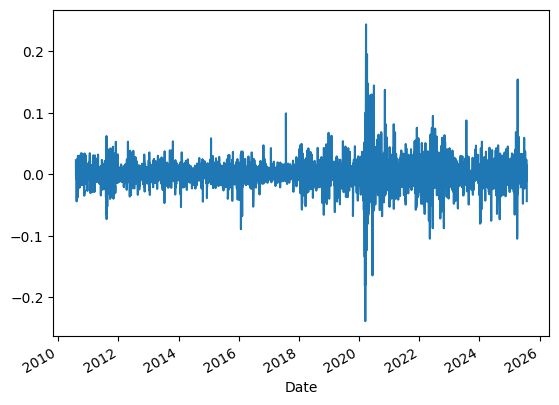

In [9]:
test_stock.pct_change().dropna().plot()

In [13]:
daily_returns = test_stock.pct_change().dropna()
print(daily_returns)

Date
2010-08-02    0.022689
2010-08-03   -0.002182
2010-08-04    0.002005
2010-08-05   -0.007821
2010-08-06   -0.000183
                ...   
2025-07-23    0.023634
2025-07-24   -0.011160
2025-07-25    0.007740
2025-07-28    0.014374
2025-07-29   -0.043695
Name: BA UN, Length: 3772, dtype: float64


/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_12154/292631666.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  daily_returns = test_stock.pct_change().dropna()


In [15]:
daily_returns_lagged_1 = daily_returns.shift(1)
print(daily_returns_lagged_1)

Date
2010-08-02         NaN
2010-08-03    0.022689
2010-08-04   -0.002182
2010-08-05    0.002005
2010-08-06   -0.007821
                ...   
2025-07-23   -0.003663
2025-07-24    0.023634
2025-07-25   -0.011160
2025-07-28    0.007740
2025-07-29    0.014374
Name: BA UN, Length: 3772, dtype: float64


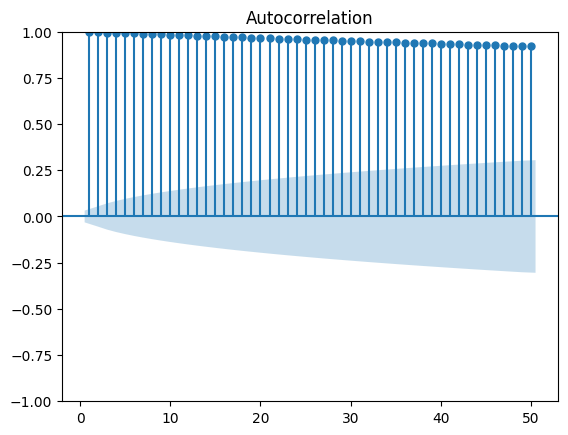

In [218]:
plot_acf(vz_us.dropna(), lags= 50, zero=False)
plt.show()

Date
2010-07-30    34.3300
2010-08-06    34.9940
2010-08-13    34.6460
2010-08-20    34.0640
2010-08-27    32.7800
               ...   
2025-07-04    91.9275
2025-07-11    91.0360
2025-07-18    91.3900
2025-07-25    91.6540
2025-08-01    90.7600
Freq: W-FRI, Name: L UN, Length: 784, dtype: float64


<Figure size 800x400 with 0 Axes>

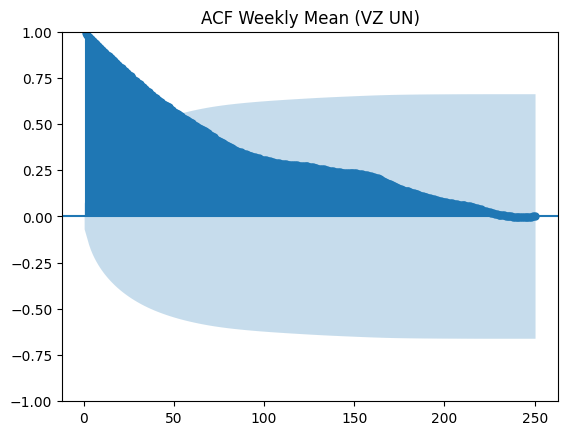

In [219]:
# ...existing code...
weekly_series = df["L UN"].resample("W-FRI").mean()   # weekly mean ending Friday
weekly_series = weekly_series.dropna()
print(weekly_series)

from statsmodels.graphics.tsaplots import plot_acf
plt.figure(figsize=(8,4))
plot_acf(weekly_series, lags=250, zero=False)
plt.title("ACF Weekly Mean (VZ UN)")
plt.show()
# ...existing code...

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_58904/931237732.py:3: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  vz_us_returns = vz_us.pct_change().dropna()


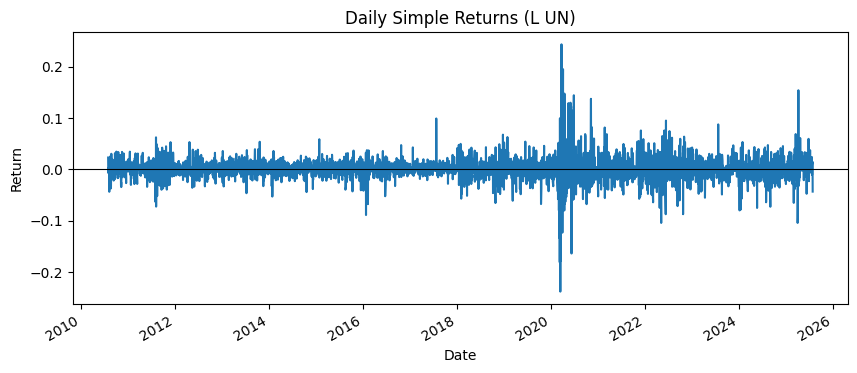

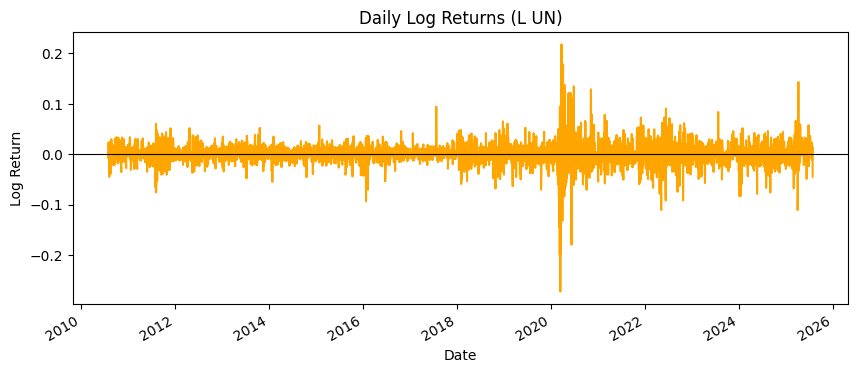

In [220]:
# ...existing code...
# Daily simple return
vz_us_returns = vz_us.pct_change().dropna()

plt.figure(figsize=(10,4))
vz_us_returns.plot(title="Daily Simple Returns (L UN)")
plt.ylabel("Return")
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

# Optional: log returns
vz_us_log_returns = np.log(vz_us / vz_us.shift(1)).dropna()

plt.figure(figsize=(10,4))
vz_us_log_returns.plot(title="Daily Log Returns (L UN)", color='orange')
plt.ylabel("Log Return")
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

In [1]:
vz_us_returns = vz_us.pct_change().dropna()


NameError: name 'vz_us' is not defined

In [12]:
percentage_change = vz_us.pct_change()
print(percentage_change)

NameError: name 'vz_us' is not defined

<Axes: xlabel='Date'>

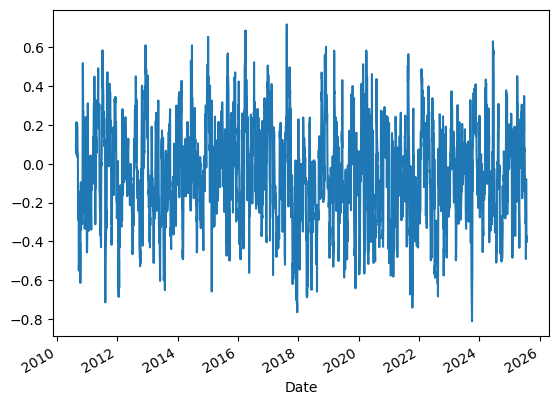

In [222]:
window = 14
correlation_score = percentage_change.rolling(window=window).corr(percentage_change.shift(1))
correlation_score.plot()

In [223]:
print(correlation_score)

Date
2010-07-30         NaN
2010-08-02         NaN
2010-08-03         NaN
2010-08-04         NaN
2010-08-05         NaN
                ...   
2025-07-23   -0.209474
2025-07-24   -0.347526
2025-07-25   -0.405845
2025-07-28   -0.373671
2025-07-29   -0.393859
Name: BA UN, Length: 3773, dtype: float64


In [224]:
rsi_inicator = RSIIndicator(close=vz_us, window=14)
vz_us_rsi = rsi_inicator.rsi()
print(vz_us_rsi)

Date
2010-07-30          NaN
2010-08-02          NaN
2010-08-03          NaN
2010-08-04          NaN
2010-08-05          NaN
                ...    
2025-07-23    72.938677
2025-07-24    67.319126
2025-07-25    69.078666
2025-07-28    72.105575
2025-07-29    54.416291
Name: rsi, Length: 3773, dtype: float64


In [375]:
def calculate_trend_reversion_score(price_series, ac_window=14, rsi_window=14):
    
    # Calculating auto correlation score
    returns = price_series.pct_change()
    score_ac = returns.rolling(window=ac_window).corr(returns.shift(1))


    # --- 2. RSI Momentum Score (Score_RSI) ---
    rsi = RSIIndicator(close=price_series, window=rsi_window).rsi()
    
    # Define RSI zones
    rsi_oversold = 30
    rsi_overbought = 70
    rsi_strong_down = 40
    rsi_strong_up = 60

    score_rsi = np.select(
        [
            rsi > rsi_overbought,  # Overbought -> Mean Reversion signal
            rsi < rsi_oversold,    # Oversold -> Mean Reversion signal
            rsi.between(rsi_strong_up, rsi_overbought), # Strong uptrend momentum -> Trend signal
            rsi.between(rsi_oversold, rsi_strong_down), # Strong downtrend momentum -> Trend signal
        ],
        [
            -1 * ((rsi - rsi_overbought) / (100 - rsi_overbought)), # Scale from 0 to -1
            -1 * ((rsi_oversold - rsi) / rsi_oversold),             # Scale from 0 to -1
            1, # Strong trend
            1  # Strong trend
        ],
        default=0 # Neutral zone
    )

    # --- 3. Combine for Final Score ---
    weights = {"AC": 0.7, "RSI": 0.3}
    total_score = (weights['AC'] * score_ac + weights['RSI'] * score_rsi)

    return total_score.dropna()

In [376]:
calculate_trend_reversion_score(vz_us)


/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_58904/1270918401.py:4: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = price_series.pct_change()


Date
2010-08-20    0.366445
2010-08-23    0.003136
2010-08-24    0.010319
2010-08-25   -0.038814
2010-08-26    0.026678
                ...   
2025-07-23   -0.176019
2025-07-24    0.056732
2025-07-25    0.015908
2025-07-28   -0.282625
2025-07-29   -0.275701
Name: BA UN, Length: 3758, dtype: float64

In [377]:
def backtest_trend_reversion_score(price_series, score_threshold = 0.3, lookback_window = 14, prediction_window = 14):
    scores = calculate_trend_reversion_score(price_series, ac_window=lookback_window, rsi_window=lookback_window)

    aligned_data = pd.DataFrame({
        'price': price_series,
        'score': scores
    }).dropna()

    aligned_data["rolling_mean"] = aligned_data["price"].rolling(window=lookback_window).mean()

    aligned_data = aligned_data.dropna()

    predictions = []
    

    for i in range(len(aligned_data) - prediction_window):
        current_date = aligned_data.index[i]
        current_price = aligned_data.iloc[i]['price']
        current_score = aligned_data.iloc[i]['score']
        current_rolling_mean = aligned_data.iloc[i]['rolling_mean']

        future_price = aligned_data.iloc[i + prediction_window]['price']
        price_change_pct = (future_price - current_price) / current_price


        if current_score <= -score_threshold:
            if current_price > current_rolling_mean: # Price is above mean, so predict it will revert down
                prediction = "revert_down"
                actual_outcome = "correct" if price_change_pct <= 0 else "incorrect"
            else: # Price went down, so predict it will revert up
                prediction = "revert_up"
                actual_outcome = "correct" if price_change_pct > 0 else "incorrect"

            predictions.append({
            'date': current_date,
            'price': current_price,
            'score': current_score,
            'prediction': prediction,
            'future_price': future_price,
            'price_change_pct': price_change_pct,
            'outcome': actual_outcome
            })    

        elif current_score >= score_threshold:
            prediction = "trending"
            if current_price > current_rolling_mean: # Price is going up, so predict it will keep going up
                prediction = "keep_trend_up"
                actual_outcome = "correct" if price_change_pct >= 0 else "incorrect"
            else: # Price went down, so predict it will keep going down
                prediction = "keep_trend_down"
                actual_outcome = "correct" if price_change_pct < 0 else "incorrect"

            predictions.append({
            'date': current_date,
            'price': current_price,
            'score': current_score,
            'prediction': prediction,
            'future_price': future_price,
            'price_change_pct': price_change_pct,
            'outcome': actual_outcome
            })
        
        else:
            continue        
        
    # Convert to DataFrame for analysis
    results_df = pd.DataFrame(predictions)
    
    if len(results_df) == 0:
        return {"error": "No predictions made. Try lowering the score_threshold."}
    
    # Calculate accuracy metrics
    total_predictions = len(results_df)
    correct_predictions = len(results_df[results_df['outcome'] == 'correct'])
    overall_accuracy = correct_predictions / total_predictions * 100

    print("Total predictions made:", total_predictions)
    print("Correct predictions:", correct_predictions)

 

    return overall_accuracy


In [378]:
backtest_trend_reversion_score(df["ACI UN"], score_threshold=0.3, lookback_window=120, prediction_window=14)




Total predictions made: 20
Correct predictions: 17


85.0

In [379]:

stock_columns = df.columns.tolist()[1:]
stock_len = len(stock_columns)
total_accuracy = 0

for stock_symbol in stock_columns:
    stock_data = df[stock_symbol]
    stock_data = pd.to_numeric(stock_data, errors='coerce').dropna()
    accuracy = backtest_trend_reversion_score(stock_data, score_threshold=0.3, lookback_window=120, prediction_window=14)
    if isinstance(accuracy, dict):
        stock_len -= 1
    else:    
        total_accuracy += accuracy

print("total accuracy:", total_accuracy / stock_len)

Total predictions made: 60
Correct predictions: 23
Total predictions made: 126
Correct predictions: 73
Total predictions made: 15
Correct predictions: 10
Total predictions made: 335
Correct predictions: 223
Total predictions made: 172
Correct predictions: 88
Total predictions made: 182
Correct predictions: 147
Total predictions made: 39
Correct predictions: 28
Total predictions made: 150
Correct predictions: 85
Total predictions made: 47
Correct predictions: 17
Total predictions made: 11
Correct predictions: 4
Total predictions made: 159
Correct predictions: 126
Total predictions made: 27
Correct predictions: 10
Total predictions made: 157
Correct predictions: 125
Total predictions made: 97
Correct predictions: 46
Total predictions made: 18
Correct predictions: 5
Total predictions made: 48
Correct predictions: 24
Total predictions made: 146
Correct predictions: 107
Total predictions made: 65
Correct predictions: 46
Total predictions made: 43
Correct predictions: 16
Total predictions ma

In [384]:
test = [1,2,3,4,5,6,7,8,9,8,7,6,5,4,3,2,1,2,3,4]
test_data = pd.Series(test)
correlation_score = test_data.rolling(window=4).corr(test_data.shift(1))
print(correlation_score)

0          NaN
1          NaN
2          NaN
3          NaN
4     1.000000
5     1.000000
6     1.000000
7     1.000000
8     1.000000
9     0.632456
10    0.000000
11    0.632456
12    1.000000
13    1.000000
14    1.000000
15    1.000000
16    1.000000
17    0.632456
18    0.000000
19    0.632456
dtype: float64


Visualizing VZ predictions...


/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_58904/334975336.py:4: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = price_series.pct_change()


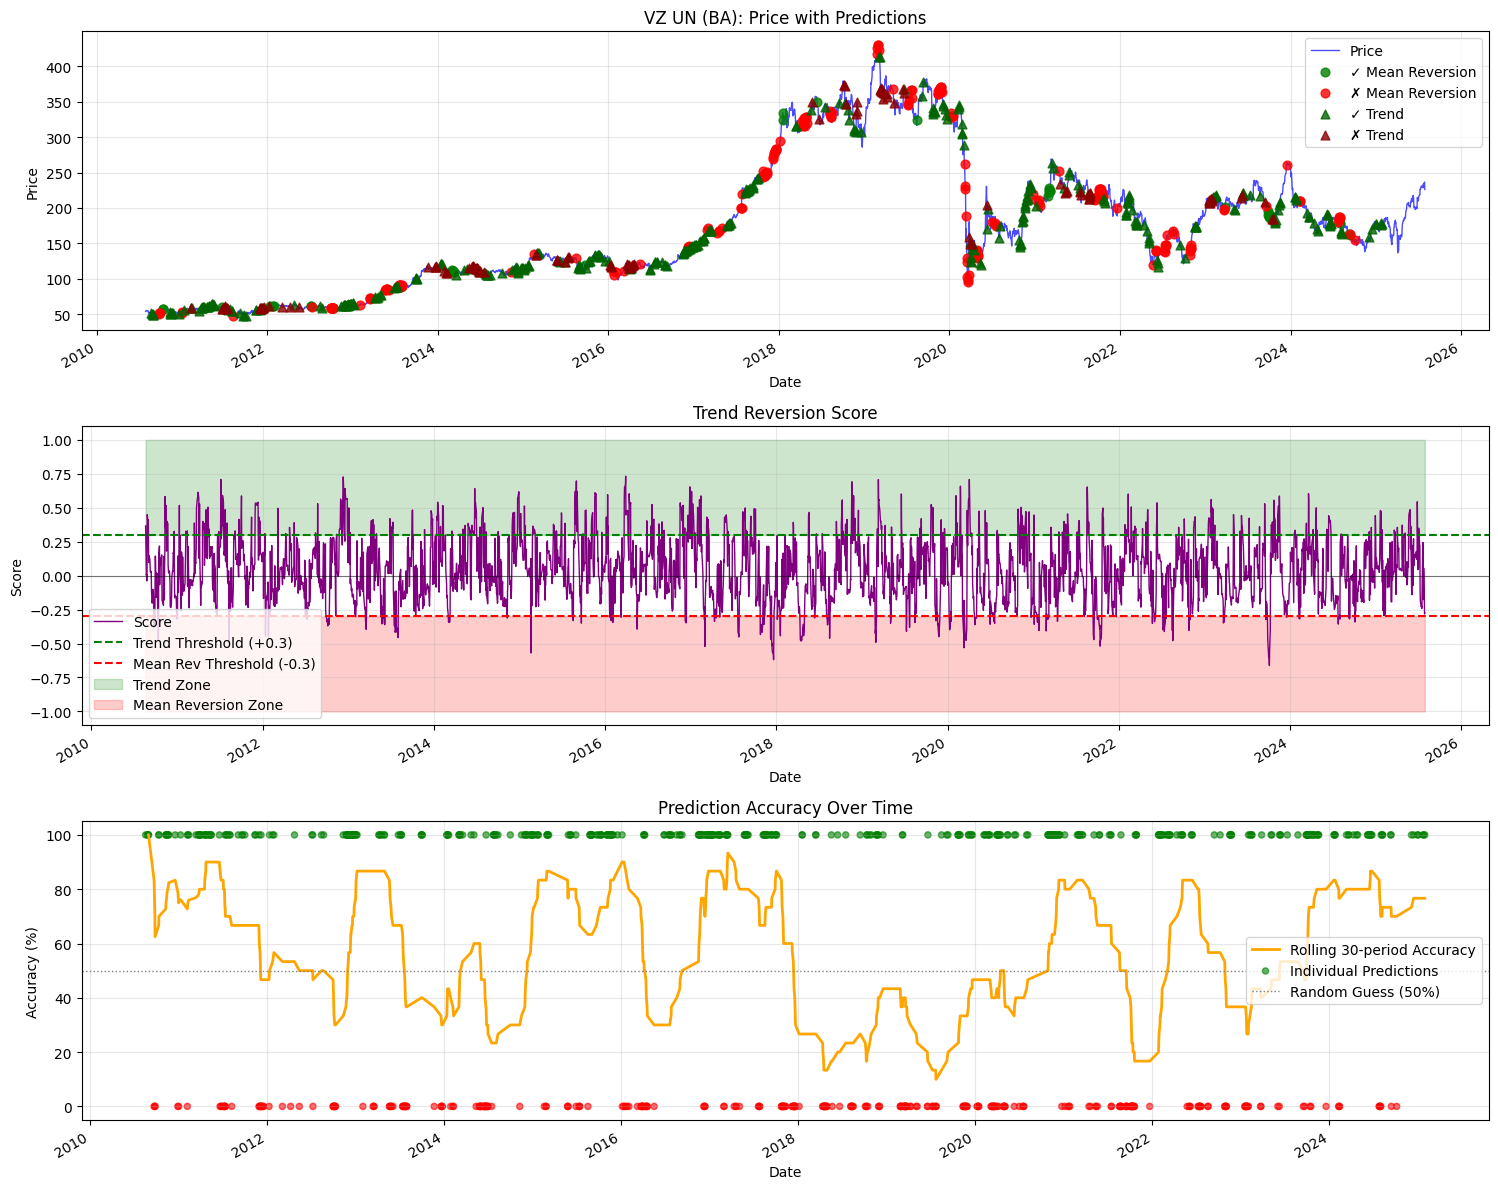


📊 PREDICTION SUMMARY for VZ UN (BA)
Overall Accuracy: 56.9% (453/796)
Mean Reversion Accuracy: 15.2%
Trend Accuracy: 75.4%
Mean Reversion Predictions: 244
Trend Predictions: 552

Visualizing Apple predictions...


/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_58904/334975336.py:4: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = price_series.pct_change()


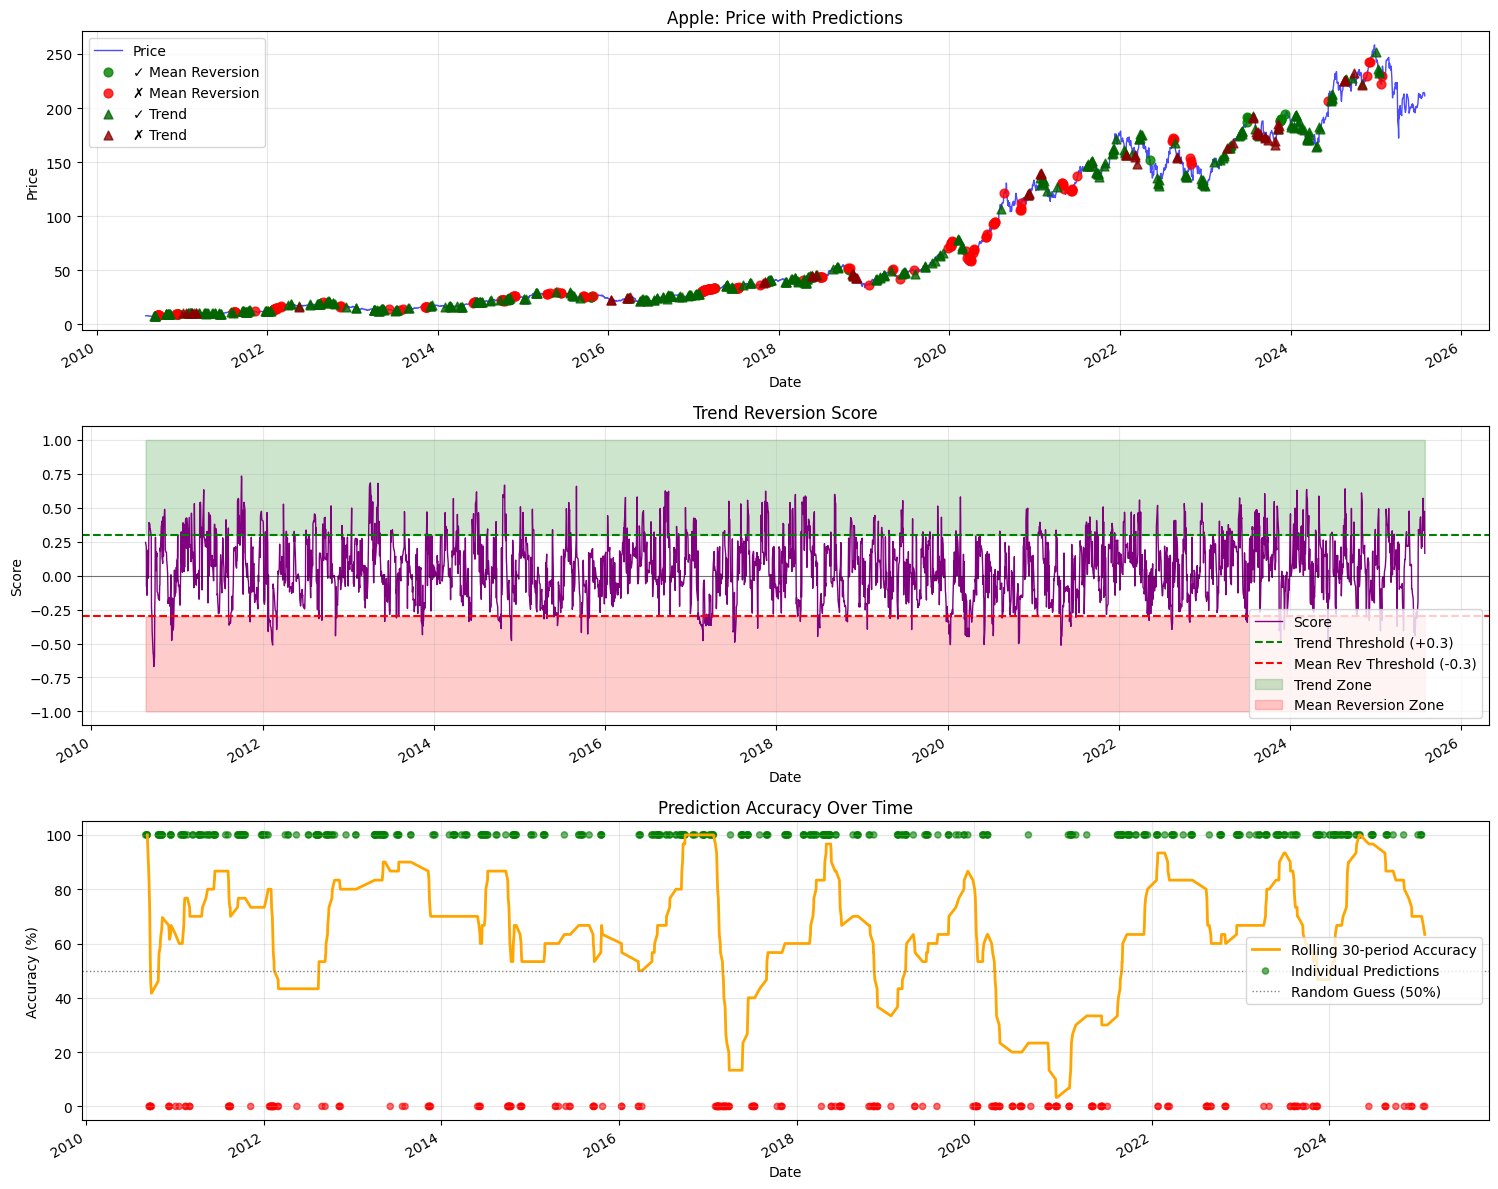


📊 PREDICTION SUMMARY for Apple
Overall Accuracy: 65.4% (474/725)
Mean Reversion Accuracy: 10.1%
Trend Accuracy: 87.6%
Mean Reversion Predictions: 208
Trend Predictions: 517


In [266]:
# Add this function to visualize predictions for a single stock:

def visualize_predictions(price_series, stock_name="Stock", score_threshold=0.3, prediction_window=14, price_threshold=0.05):
    """
    Create comprehensive visualizations of trend reversion predictions.
    """
    # Calculate scores and run backtest
    scores = calculate_trend_reversion_score(price_series)
    
    # Get detailed prediction results
    aligned_data = pd.DataFrame({
        'price': price_series,
        'score': scores
    }).dropna()
    
    predictions = []
    
    for i in range(len(aligned_data) - prediction_window):
        current_date = aligned_data.index[i]
        current_price = aligned_data.iloc[i]['price']
        current_score = aligned_data.iloc[i]['score']
        future_price = aligned_data.iloc[i + prediction_window]['price']
        price_change_pct = (future_price - current_price) / current_price
        
        if current_score <= -score_threshold:
            prediction = "mean_reversion"
            actual_outcome = "correct" if abs(price_change_pct) <= price_threshold else "incorrect"
        elif current_score >= score_threshold:
            prediction = "trend"
            actual_outcome = "correct" if abs(price_change_pct) > price_threshold else "incorrect"
        else:
            continue
        
        predictions.append({
            'date': current_date,
            'price': current_price,
            'score': current_score,
            'prediction': prediction,
            'outcome': actual_outcome,
            'price_change_pct': price_change_pct,
            'future_price': future_price
        })
    
    if not predictions:
        print("No predictions to visualize!")
        return
    
    results_df = pd.DataFrame(predictions)
    
    # Create visualization
    fig, axes = plt.subplots(3, 1, figsize=(15, 12))
    
    # Plot 1: Price with prediction markers
    ax1 = axes[0]
    price_series.plot(ax=ax1, color='blue', alpha=0.7, linewidth=1, label='Price')
    
    # Color-code predictions
    correct_mean_rev = results_df[(results_df['prediction'] == 'mean_reversion') & (results_df['outcome'] == 'correct')]
    incorrect_mean_rev = results_df[(results_df['prediction'] == 'mean_reversion') & (results_df['outcome'] == 'incorrect')]
    correct_trend = results_df[(results_df['prediction'] == 'trend') & (results_df['outcome'] == 'correct')]
    incorrect_trend = results_df[(results_df['prediction'] == 'trend') & (results_df['outcome'] == 'incorrect')]
    
    ax1.scatter(correct_mean_rev['date'], correct_mean_rev['price'], 
               color='green', marker='o', s=40, label='✓ Mean Reversion', alpha=0.8, zorder=5)
    ax1.scatter(incorrect_mean_rev['date'], incorrect_mean_rev['price'], 
               color='red', marker='o', s=40, label='✗ Mean Reversion', alpha=0.8, zorder=5)
    ax1.scatter(correct_trend['date'], correct_trend['price'], 
               color='darkgreen', marker='^', s=40, label='✓ Trend', alpha=0.8, zorder=5)
    ax1.scatter(incorrect_trend['date'], incorrect_trend['price'], 
               color='darkred', marker='^', s=40, label='✗ Trend', alpha=0.8, zorder=5)
    
    ax1.set_title(f'{stock_name}: Price with Predictions')
    ax1.set_ylabel('Price')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: Trend Reversion Score
    ax2 = axes[1]
    scores.plot(ax=ax2, color='purple', linewidth=1, label='Score')
    ax2.axhline(score_threshold, color='green', linestyle='--', label=f'Trend Threshold (+{score_threshold})')
    ax2.axhline(-score_threshold, color='red', linestyle='--', label=f'Mean Rev Threshold (-{score_threshold})')
    ax2.axhline(0, color='black', linestyle='-', alpha=0.5, linewidth=0.8)
    ax2.fill_between(scores.index, score_threshold, 1, alpha=0.2, color='green', label='Trend Zone')
    ax2.fill_between(scores.index, -score_threshold, -1, alpha=0.2, color='red', label='Mean Reversion Zone')
    
    ax2.set_title('Trend Reversion Score')
    ax2.set_ylabel('Score')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # Plot 3: Prediction accuracy over time
    ax3 = axes[2]
    results_df['correct_numeric'] = (results_df['outcome'] == 'correct').astype(int)
    results_df_indexed = results_df.set_index('date')
    
    # Rolling accuracy
    window_size = min(30, len(results_df) // 5)  # Adaptive window size
    if window_size > 5:
        rolling_accuracy = results_df_indexed['correct_numeric'].rolling(
            window=window_size, min_periods=5).mean() * 100
        rolling_accuracy.plot(ax=ax3, color='orange', linewidth=2, label=f'Rolling {window_size}-period Accuracy')
    
    # Individual predictions
    ax3.scatter(results_df['date'], results_df['correct_numeric'] * 100, 
               c=['green' if x == 'correct' else 'red' for x in results_df['outcome']], 
               alpha=0.6, s=20, label='Individual Predictions')
    
    ax3.axhline(50, color='gray', linestyle=':', label='Random Guess (50%)', linewidth=1)
    ax3.set_title('Prediction Accuracy Over Time')
    ax3.set_ylabel('Accuracy (%)')
    ax3.set_xlabel('Date')
    ax3.set_ylim(-5, 105)
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    total_predictions = len(results_df)
    correct_predictions = len(results_df[results_df['outcome'] == 'correct'])
    accuracy = correct_predictions / total_predictions * 100
    
    mean_rev_accuracy = len(correct_mean_rev) / len(results_df[results_df['prediction'] == 'mean_reversion']) * 100 if len(results_df[results_df['prediction'] == 'mean_reversion']) > 0 else 0
    trend_accuracy = len(correct_trend) / len(results_df[results_df['prediction'] == 'trend']) * 100 if len(results_df[results_df['prediction'] == 'trend']) > 0 else 0
    
    print(f"\n📊 PREDICTION SUMMARY for {stock_name}")
    print("=" * 50)
    print(f"Overall Accuracy: {accuracy:.1f}% ({correct_predictions}/{total_predictions})")
    print(f"Mean Reversion Accuracy: {mean_rev_accuracy:.1f}%")
    print(f"Trend Accuracy: {trend_accuracy:.1f}%")
    print(f"Mean Reversion Predictions: {len(results_df[results_df['prediction'] == 'mean_reversion'])}")
    print(f"Trend Predictions: {len(results_df[results_df['prediction'] == 'trend'])}")
    
    return results_df

# Test with your VZ data
print("Visualizing VZ predictions...")
vz_results = visualize_predictions(vz_us, "VZ UN (BA)", score_threshold=0.3, prediction_window=120)

# Test with Apple data
print("\nVisualizing Apple predictions...")
apple_results = visualize_predictions(df["AAPL UW"], "Apple", score_threshold=0.3, prediction_window=120)

<Axes: xlabel='Date'>

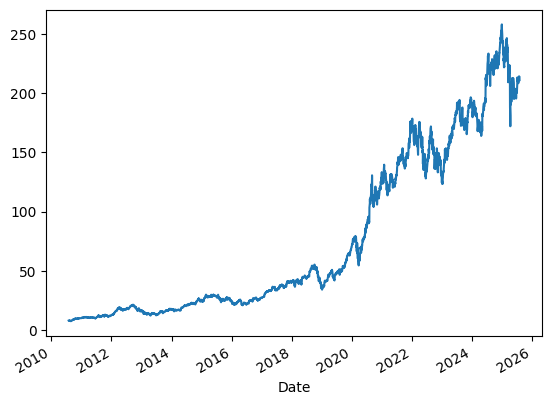

In [244]:
apple = df["AAPL UW"]
apple.plot()

<Axes: xlabel='Date'>

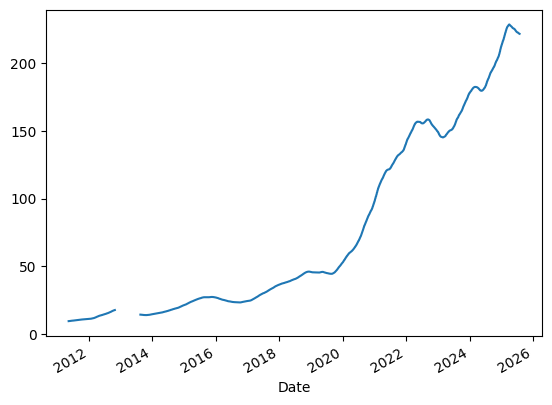

In [253]:
ma_window = 200
moving_average = apple.rolling(window=ma_window).mean()
moving_average.plot()
    

Date
2010-07-30         NaN
2010-08-02         NaN
2010-08-03         NaN
2010-08-04         NaN
2010-08-05         NaN
                ...   
2025-07-23    -7.63160
2025-07-24    -7.96600
2025-07-25    -7.78535
2025-07-28    -7.58105
2025-07-29   -10.29250
Name: AAPL UW, Length: 3773, dtype: float64


<Axes: xlabel='Date'>

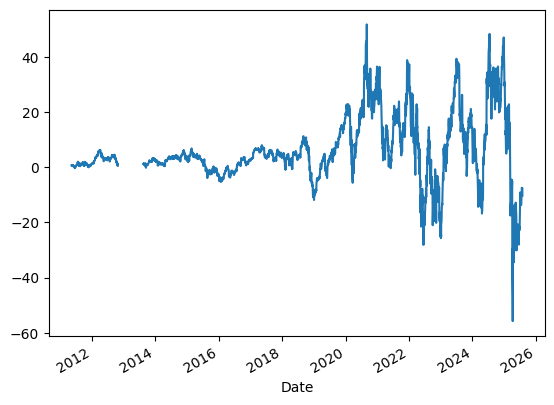

In [254]:
# calculate how the data deviate from the mean
deviation = apple - moving_average
print(deviation)
deviation.plot()



In [247]:
the_mean = 0
above_mean = deviation > 0


In [255]:
crossing = (above_mean != above_mean.shift(1)) & (above_mean.shift(1).notna())
crossing_dates = vz_us[crossing].index
print(crossing_dates)

DatetimeIndex(['2015-08-12', '2016-01-27', '2016-01-29', '2016-02-02',
               '2016-02-03', '2016-02-05', '2016-02-08', '2016-02-10',
               '2016-02-16', '2016-02-23', '2016-02-24', '2016-04-27',
               '2016-05-25', '2016-06-02', '2016-06-06', '2016-06-13',
               '2016-07-18', '2016-07-21', '2016-07-27', '2018-12-24',
               '2018-12-26', '2019-01-03', '2019-01-08', '2022-12-19',
               '2022-12-21', '2022-12-22', '2023-01-13', '2025-04-07',
               '2025-04-09'],
              dtype='datetime64[ns]', name='Date', freq=None)


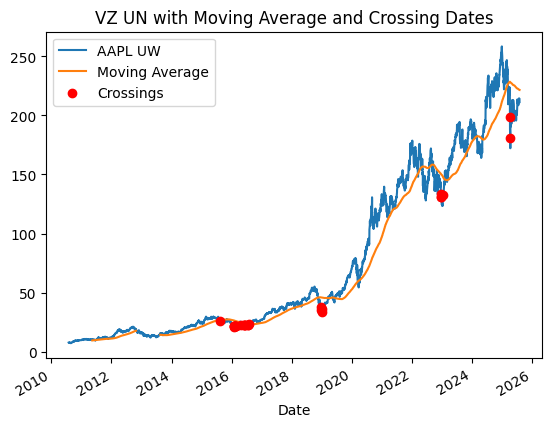

In [263]:

apple.plot(label="AAPL UW")
moving_average.plot(label="Moving Average")

# Mark crossing dates
plt.scatter(crossing_dates, apple[crossing_dates], color='red', label='Crossings', zorder=3)

plt.legend()
plt.title("VZ UN with Moving Average and Crossing Dates")
plt.show()

In [260]:
time_between_crossings = pd.Series(crossing_dates).diff().dt.days.dropna()
print(time_between_crossings.unique())


[1.680e+02 2.000e+00 4.000e+00 1.000e+00 3.000e+00 6.000e+00 7.000e+00
 6.300e+01 2.800e+01 8.000e+00 3.500e+01 8.800e+02 5.000e+00 1.441e+03
 2.200e+01 8.150e+02]


In [261]:
#average crossing time - extension will be a more robust model with more explanatory variables and deternmining where you are in the mean reverse cycle
average_crossing_time = time_between_crossings.mean()
print(average_crossing_time)

median_crossing_time = time_between_crossings.median()
print(median_crossing_time)

126.0
5.5


<Axes: xlabel='Date'>

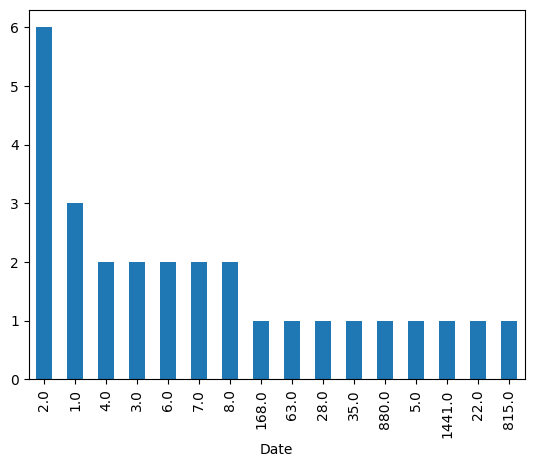

In [262]:
time_between_crossings_count = time_between_crossings.value_counts()
time_between_crossings_count.plot.bar()